# Credit Risk Analytics: Predicting Loan Default

End-to-end walkthrough on a **synthetic** 5,000-loan dataset: cleaning, EDA, model comparison, cross-validation, drivers of default, probability calibration and cost-based threshold selection.

Run `python src/cleaning.py`, `python src/eda.py` and `python src/model.py` first (or `python src/run_all.py`) so the report files used below exist.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append('../src')
from cleaning import clean_data

pd.set_option('display.width', 160)
df = clean_data(pd.read_csv('../data/raw/loan_applications.csv'))
df.head()

,loan_id,customer_id,age,annual_income,employment_status,employment_length_years,credit_score,loan_amount,loan_term_months,interest_rate,existing_loans,previous_defaults,debt_to_income_ratio,home_ownership,loan_purpose,application_channel,default,credit_score_band,income_band,loan_to_income_ratio
0,L100000,C200000,25,419597.0,Contract,10.1,614,226905.0,36,19.11,0,0,0.306,Rent,Personal,Branch,0,Fair,Lower-Middle,0.5408
1,L100001,C200001,55,326461.0,Employed,0.1,716,108480.0,60,14.09,0,1,0.214,Mortgage,Debt Consolidation,Branch,0,Good,Lower-Middle,0.3323
2,L100002,C200002,50,641100.0,Employed,6.5,666,171563.0,36,14.42,2,0,0.306,Mortgage,Business,Website,0,Fair,High,0.2676
3,L100003,C200003,40,659025.0,Employed,10.6,650,48259.0,12,15.49,1,0,0.296,Own,Debt Consolidation,Branch,0,Fair,High,0.0732
4,L100004,C200004,40,312923.0,Employed,7.2,596,189858.0,24,17.14,1,0,0.319,Own,Personal,Branch,0,Fair,Lower-Middle,0.6067


## 1. Portfolio overview

In [2]:
print('Shape:', df.shape)
print('Default rate:', round(df['default'].mean() * 100, 2), '%')
df.describe().T.round(2)

Shape: (5000, 20)
Default rate: 17.56 %


,count,mean,std,min,25%,50%,75%,max
age,5000.0,42.94,13.02,21.00,32.00,43.00,54.00,65.00
annual_income,5000.0,492379.12,293308.91,90000.00,292445.25,419597.00,608614.50,2500000.00
employment_length_years,5000.0,6.72,4.21,0.00,3.60,6.50,9.60,20.90
credit_score,5000.0,659.33,75.64,356.00,607.00,660.00,711.00,850.00
loan_amount,5000.0,236871.42,183041.10,10000.00,110137.25,190663.50,315874.75,1000000.00
loan_term_months,5000.0,39.87,16.57,12.00,24.00,36.00,48.00,72.00
interest_rate,5000.0,15.89,1.95,9.06,14.55,15.90,17.24,23.34
existing_loans,5000.0,1.48,1.21,0.00,1.00,1.00,2.00,7.00
previous_defaults,5000.0,0.36,0.59,0.00,0.00,0.00,1.00,4.00
debt_to_income_ratio,5000.0,0.30,0.09,0.02,0.24,0.30,0.36,0.63


## 2. Observed default rate by credit-score band

,mean,count
credit_score_band,,
Poor,0.465,742
Fair,0.195,1995
Good,0.080,1536
Very Good,0.029,727


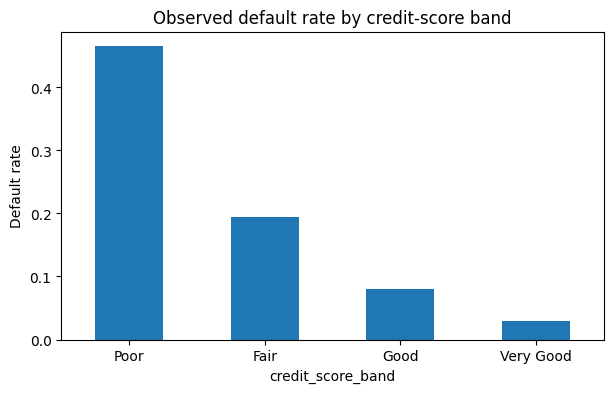

In [3]:
by_band = df.groupby('credit_score_band', observed=False)['default'].agg(['mean', 'count']).round(3)
display(by_band)
ax = by_band['mean'].plot(kind='bar', figsize=(7, 4), title='Observed default rate by credit-score band')
ax.set_ylabel('Default rate'); plt.xticks(rotation=0); plt.show()

## 3. Other risk segments

In [4]:
for col in ['previous_defaults', 'employment_status', 'loan_purpose']:
    display(df.groupby(col)['default'].agg(['mean', 'count']).round(3).sort_values('mean', ascending=False))

,mean,count
previous_defaults,,
4,0.500,2
3,0.370,27
2,0.330,209
1,0.211,1301
0,0.151,3461


,mean,count
employment_status,,
Unemployed,0.310,252
Contract,0.191,617
Self-employed,0.182,948
Employed,0.160,3183


,mean,count
loan_purpose,,
Debt Consolidation,0.201,985
Home Improvement,0.186,725
Personal,0.177,1026
Vehicle,0.175,1091
Business,0.160,569
Education,0.134,604


## 4. Model comparison (20% hold-out set)

In [5]:
pd.read_csv('../reports/model_comparison.csv').round(3)

,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Logistic Regression,0.767,0.410,0.739,0.527,0.831,0.545
1,Random Forest,0.801,0.451,0.597,0.513,0.817,0.523
2,Decision Tree,0.731,0.367,0.727,0.488,0.791,0.490


## 5. Cross-validation (5-fold, stratified)

The hold-out ROC-AUC (0.83) is on the favourable side; the cross-validated mean is the more reliable estimate of performance.

In [6]:
pd.read_csv('../reports/cross_validation.csv').round(3)

,model,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,precision_mean,precision_std,recall_mean,recall_std
0,Logistic Regression,0.794,0.022,0.496,0.041,0.355,0.015,0.710,0.033
1,Random Forest,0.786,0.023,0.472,0.040,0.401,0.023,0.560,0.051
2,Decision Tree,0.728,0.022,0.390,0.024,0.317,0.025,0.668,0.065


## 6. Drivers of default (Logistic Regression odds ratios)

Numeric features are standardised, so odds ratios are per 1 standard deviation. `credit_score` and `interest_rate` are correlated (r = -0.69), so interpret their individual coefficients with care.

In [7]:
odds = pd.read_csv('../reports/logistic_odds_ratios.csv')
odds.head(10).round(3)

,feature,coefficient,odds_ratio
0,credit_score,-0.880,0.415
1,interest_rate,0.374,1.453
2,previous_defaults,0.345,1.411
3,existing_loans,0.268,1.307
4,loan_purpose_Education,-0.232,0.793
5,employment_status_Employed,-0.208,0.812
6,income_band_Upper-Middle,-0.199,0.820
7,employment_status_Unemployed,0.185,1.204
8,loan_purpose_Debt Consolidation,0.184,1.202
9,income_band_Low,0.181,1.199


In [8]:
pd.read_csv('../reports/sensitivity_no_interest_rate.csv').round(4)

,variant,roc_auc
0,All features,0.8305
1,Without interest_rate,0.8251


## 7. Probability calibration

`class_weight='balanced'` inflates predicted probabilities. Sigmoid calibration brings the mean predicted default probability back in line with the observed default rate.

In [9]:
pd.read_csv('../reports/calibration.csv').round(3)

,variant,brier_score,mean_predicted_pd,observed_default_rate
0,"Logistic Regression (balanced, uncalibrated)",0.168,0.400,0.176
1,Logistic Regression (sigmoid-calibrated),0.111,0.169,0.176


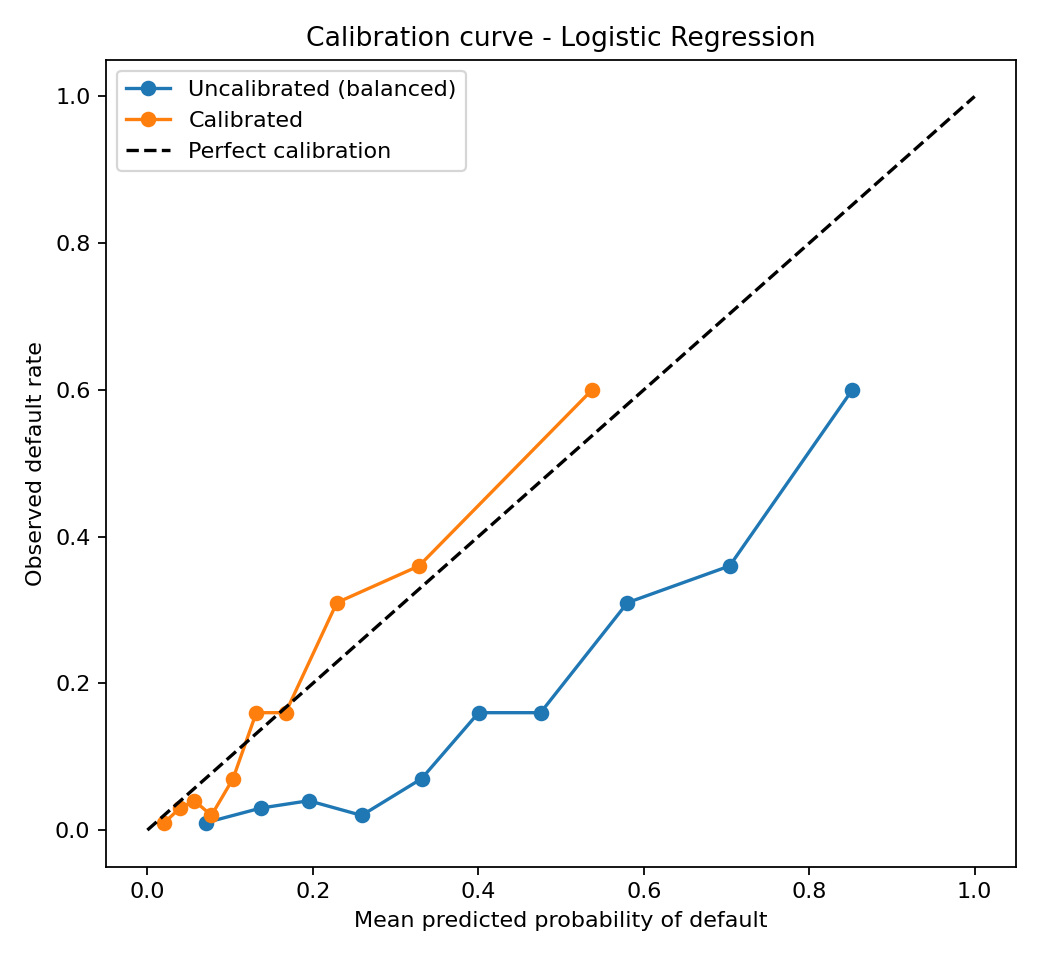

In [10]:
from IPython.display import Image
Image('../visualisations/calibration_curve.png', width=480)

## 8. Cost-based decision threshold

Thresholds are chosen on out-of-fold training predictions, then evaluated once on the hold-out set. Assumed cost: a missed defaulter costs *k* times a wrongly declined good borrower (illustrative, since the data is synthetic).

In [11]:
pd.read_csv('../reports/threshold_analysis.csv').round(3)

,fn_to_fp_cost_ratio,threshold,precision,recall,false_positives,false_negatives,total_cost_units,baseline_cost_at_0.5,cost_reduction_pct
0,1,0.48,0.662,0.244,22,133,155,233,33.476
1,3,0.24,0.460,0.614,127,68,331,325,-1.846
2,5,0.16,0.370,0.767,230,41,435,417,-4.317
3,10,0.08,0.264,0.955,469,8,549,647,15.147


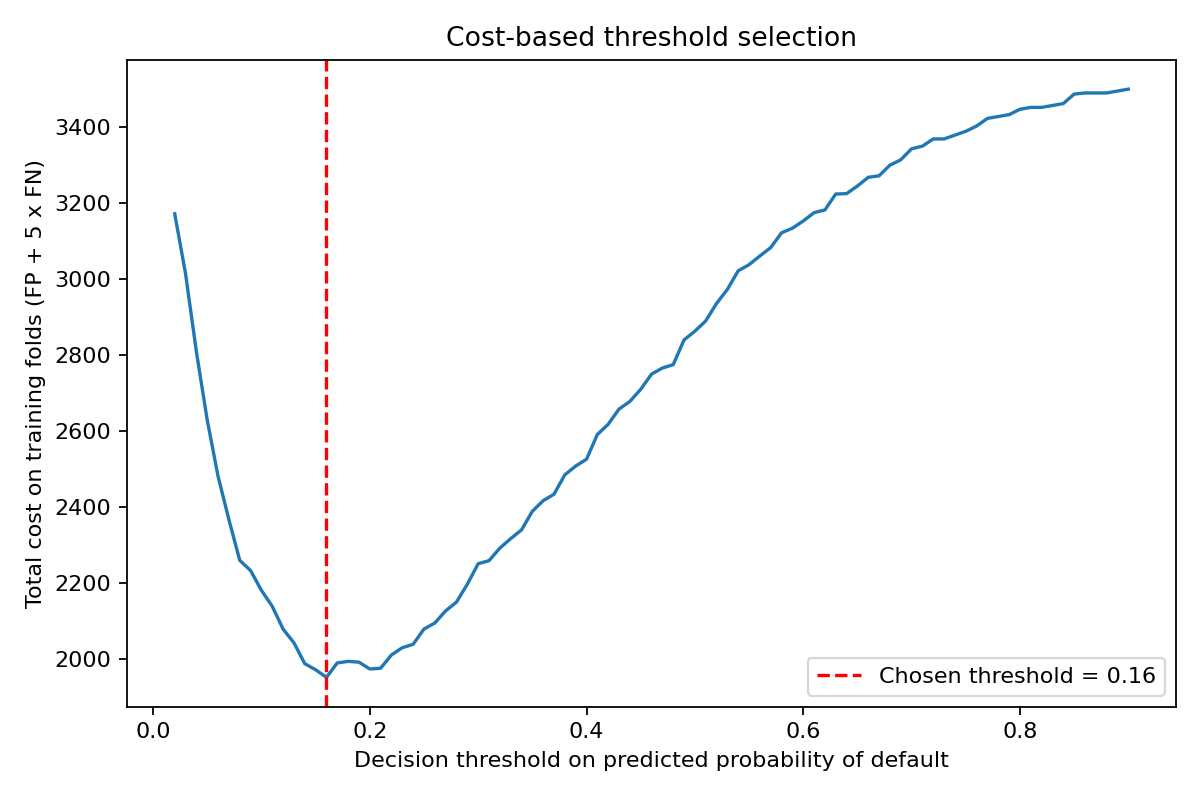

In [12]:
Image('../visualisations/threshold_cost_curve.png', width=520)

## 9. From model to credit policy

Calibrated probabilities of default are grouped into four risk tiers, each with a recommended action. Amounts are in the dataset's currency units, labelled R (millions) for readability. Assumptions: loss given default 45%, net margin 4% a year on the average balance.

In [13]:
tiers = pd.read_csv('../reports/risk_tiers.csv')
tiers[['tier','loans','share_of_loans_pct','share_of_realised_loss_pct','predicted_pd','observed_default_rate','recommended_action']].round(3)

,tier,loans,share_of_loans_pct,share_of_realised_loss_pct,predicted_pd,observed_default_rate,recommended_action
0,Low,2189,43.78,10.430,0.050,0.052,Approve
1,Medium,1639,32.78,25.881,0.163,0.157,Approve with standard conditions / risk-based ...
2,High,618,12.36,21.609,0.316,0.324,Manual underwriting review
3,Very High,554,11.08,42.079,0.551,0.554,Decline (or require security / guarantor)


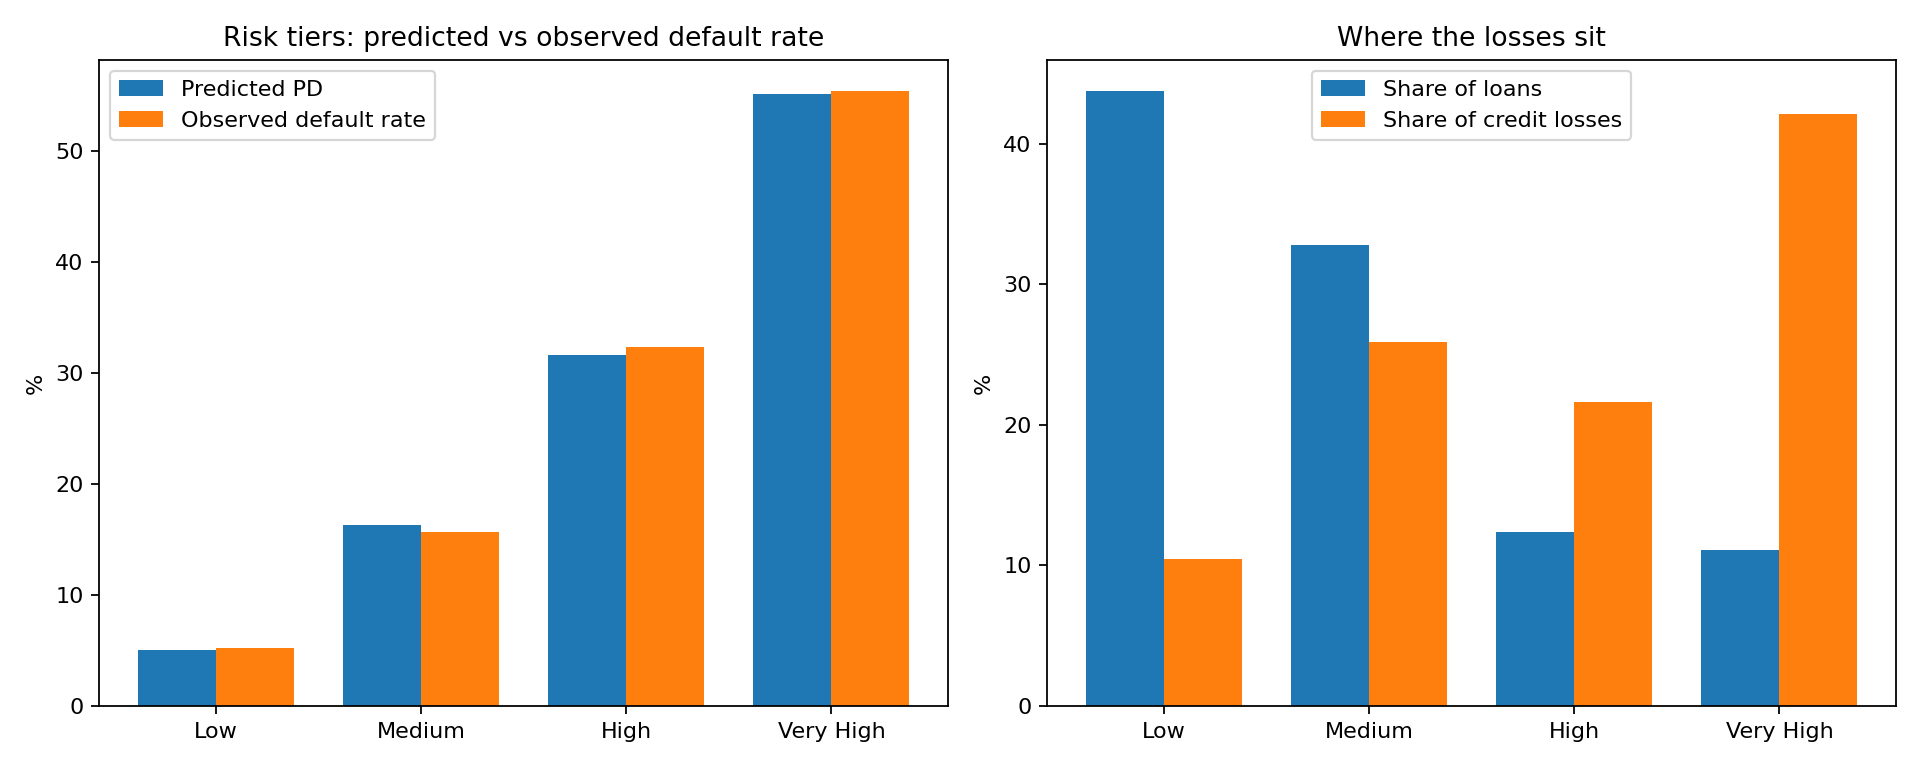

In [14]:
Image('../visualisations/risk_tiers.png', width=800)

### Back-test of two decline policies

In [15]:
pd.read_csv('../reports/policy_scenarios.csv').round(2).T

,0,1
policy,A: decline Very High tier (PD >= 40%),B: decline High and Very High tiers (PD >= 25%)
loans_declined,554,1172
share_of_loans_declined_pct,11.08,23.44
defaults_avoided,307,507
good_loans_declined,247,665
losses_avoided_Rm,45.06,68.19
margin_forgone_Rm,4.99,12.5
net_benefit_Rm,40.07,55.69
portfolio_realised_loss_Rm,107.08,107.08


### Sensitivity of the net benefit to the assumptions (R millions)

In [16]:
sens = pd.read_csv('../reports/policy_sensitivity.csv')
sens.pivot_table(index=['policy','lgd'], columns='net_margin', values='net_benefit_Rm').round(1)

net_margin                                            0.02  0.04  0.06
policy                                          lgd                   
A: decline Very High tier (PD >= 40%)           0.30  27.5  25.0  22.6
                                                0.45  42.6  40.1  37.6
                                                0.60  57.6  55.1  52.6
B: decline High and Very High tiers (PD >= 25%) 0.30  39.2  33.0  26.7
                                                0.45  61.9  55.7  49.4
                                                0.60  84.7  78.4  72.2

## Takeaways

- Credit score, interest rate, previous defaults and existing loans carry the largest model coefficients; observed default rates also rise with debt-to-income ratio and unemployment.
- Logistic Regression is the selected model: best ROC-AUC, and interpretable.
- The riskiest 23% of loans (High and Very High tiers) generate about 64% of credit losses; declining or restructuring the Very High tier alone shows a net benefit of about R40m in the back-test.
- The right decision threshold depends on the business cost ratio, not on 0.5.
- Results are from synthetic data and are not evidence the model is suitable for real lending decisions.